# 4. Policy Gradient Methods on CartPole: REINFORCE, REINFORCE with Baseline and PPO

Compares three policy-gradient algorithms on the CartPole balancing task (Gymnasium `CartPole-v0`, maximum reward 200 per episode):

1. **REINFORCE**: Monte Carlo policy gradient.
2. **REINFORCE with a baseline**: subtracts a learned state-value function to reduce the variance of the gradient.
3. **Proximal Policy Optimization (PPO)**: reuses each episode for several clipped policy updates.

All three use the same policy network (two hidden layers of 32 units) and random seed.

## Setup

In [1]:
import copy
import warnings

import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import random
import torch
import torch.nn as nn

warnings.filterwarnings("ignore")

SEED = 1
ENV_NAME = "CartPole-v0"
OBS_N, ACT_N = 4, 2
HIDDEN = 32
GAMMA = 1.0
TEST_EPISODES = 10
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


def tensor(x, dtype=torch.float32):
    return torch.tensor(np.array(x), dtype=dtype, device=DEVICE)


def mlp(out_dim):
    return nn.Sequential(
        nn.Linear(OBS_N, HIDDEN), nn.ReLU(),
        nn.Linear(HIDDEN, HIDDEN), nn.ReLU(),
        nn.Linear(HIDDEN, out_dim),
    ).to(DEVICE)


def make_policy(pi):
    def policy(obs):
        with torch.no_grad():
            probs = torch.softmax(pi(tensor(obs)), dim=-1)
        return np.random.choice(ACT_N, p=probs.cpu().numpy())
    return policy


def play_episode(env, policy):
    states, actions, rewards = [env.reset()[0]], [], []
    done = False
    while not done:
        action = policy(states[-1])
        obs, reward, terminated, truncated, _ = env.step(action)
        done = terminated or truncated
        states.append(obs)
        actions.append(action)
        rewards.append(reward)
    return states, actions, rewards


def discounted_returns(rewards):
    returns = copy.deepcopy(rewards)
    for i in range(len(rewards) - 2, -1, -1):
        returns[i] += GAMMA * returns[i + 1]
    return tensor(returns)


def log_probs_of(pi, S, A):
    return torch.log_softmax(pi(S), dim=-1).gather(1, A.view(-1, 1)).view(-1)


def run(name, pi, train, epochs, ppo=False):
    set_seed(SEED)
    env = gym.make(ENV_NAME)
    env.reset(seed=SEED)
    policy = make_policy(pi)

    episode_rewards, last25 = [], []
    for episode in range(1, epochs + 1):
        states, actions, rewards = play_episode(env, policy)
        S, A = tensor(states[:-1]), tensor(actions, dtype=torch.long)
        returns = discounted_returns(rewards)

        if ppo:
            train(S, A, returns, log_probs_of(pi, S, A).detach())
        else:
            train(S, A, returns)

        episode_rewards.append(sum(rewards))
        last25.append(np.mean(episode_rewards[-25:]))
        if episode % (epochs // 5) == 0:
            print(f"{name} | episode {episode}/{epochs} | average reward (last 25) {last25[-1]:.1f}")

    test_rewards = [sum(play_episode(env, policy)[2]) for _ in range(TEST_EPISODES)]
    env.close()
    print(f"{name}: test reward {np.mean(test_rewards):.1f} ± {np.std(test_rewards):.1f} over {TEST_EPISODES} episodes")
    return last25, test_rewards


results = {}

## REINFORCE

After each episode, the policy takes one gradient step on $-\sum_t \gamma^t G_t \log \pi(a_t \mid s_t)$, where $G_t$ is the return from step $t$.

In [2]:
set_seed(SEED)
pi = mlp(ACT_N)
opt_pi = torch.optim.Adam(pi.parameters(), lr=5e-4)


def train_reinforce(S, A, returns):
    opt_pi.zero_grad()
    n = torch.arange(S.size(0), device=DEVICE)
    loss = -((GAMMA ** n) * returns * log_probs_of(pi, S, A)).sum()
    loss.backward()
    opt_pi.step()


results["REINFORCE"] = run("REINFORCE", pi, train_reinforce, epochs=800)

REINFORCE | episode 160/800 | average reward (last 25) 27.6


REINFORCE | episode 320/800 | average reward (last 25) 44.3


REINFORCE | episode 480/800 | average reward (last 25) 116.0


REINFORCE | episode 640/800 | average reward (last 25) 172.2


REINFORCE | episode 800/800 | average reward (last 25) 192.9
REINFORCE: test reward 179.5 ± 45.6 over 10 episodes


## REINFORCE with a baseline

A value network $V(s)$ is fitted to the returns with one Monte Carlo update per step. The policy gradient then uses the advantage $G_t - V(s_t)$ instead of the raw return, which lowers the variance of the update without biasing it.

In [3]:
set_seed(SEED)
pi = mlp(ACT_N)
V = mlp(1)
opt_v = torch.optim.Adam(V.parameters(), lr=5e-4)
opt_pi = torch.optim.Adam(pi.parameters(), lr=5e-4)


def fit_value_and_advantage(S, returns):
    for n in range(S.size(0)):
        delta = returns[n] - V(S[n]).detach()
        opt_v.zero_grad()
        (-(delta * V(S[n])).sum()).backward()
        opt_v.step()
    return (returns - V(S).view(-1)).detach()


def train_reinforce_baseline(S, A, returns):
    advantage = fit_value_and_advantage(S, returns)
    opt_pi.zero_grad()
    n = torch.arange(S.size(0), device=DEVICE)
    loss = -((GAMMA ** n) * advantage * log_probs_of(pi, S, A)).sum()
    loss.backward()
    opt_pi.step()


results["REINFORCE with baseline"] = run("REINFORCE with baseline", pi, train_reinforce_baseline, epochs=800)

REINFORCE with baseline | episode 160/800 | average reward (last 25) 27.7


REINFORCE with baseline | episode 320/800 | average reward (last 25) 56.0


REINFORCE with baseline | episode 480/800 | average reward (last 25) 163.4


REINFORCE with baseline | episode 640/800 | average reward (last 25) 183.7


REINFORCE with baseline | episode 800/800 | average reward (last 25) 200.0
REINFORCE with baseline: test reward 200.0 ± 0.0 over 10 episodes


## Proximal Policy Optimization (PPO)

Uses the same value baseline, but takes 10 policy updates per episode on the clipped surrogate objective
$\min\big(r_t A_t,\ \text{clip}(r_t, 1-\epsilon, 1+\epsilon) A_t\big)$, where $r_t$ is the ratio of the new to the old action probability and $\epsilon = 0.1$.

In [4]:
set_seed(SEED)
pi = mlp(ACT_N)
V = mlp(1)
opt_v = torch.optim.Adam(V.parameters(), lr=5e-4)
opt_pi = torch.optim.Adam(pi.parameters(), lr=5e-4)

POLICY_TRAIN_ITERS = 10
CLIP = 0.1


def train_ppo(S, A, returns, old_log_probs):
    advantage = fit_value_and_advantage(S, returns)
    for _ in range(POLICY_TRAIN_ITERS):
        ratio = torch.exp(log_probs_of(pi, S, A) - old_log_probs)
        clipped = torch.clamp(ratio, 1 - CLIP, 1 + CLIP)
        loss = -torch.min(ratio * advantage, clipped * advantage).mean()
        opt_pi.zero_grad()
        loss.backward()
        opt_pi.step()


results["PPO"] = run("PPO", pi, train_ppo, epochs=150, ppo=True)

PPO | episode 30/150 | average reward (last 25) 22.9


PPO | episode 60/150 | average reward (last 25) 75.7


PPO | episode 90/150 | average reward (last 25) 167.0


PPO | episode 120/150 | average reward (last 25) 195.6


PPO | episode 150/150 | average reward (last 25) 198.4
PPO: test reward 200.0 ± 0.0 over 10 episodes


## Comparison

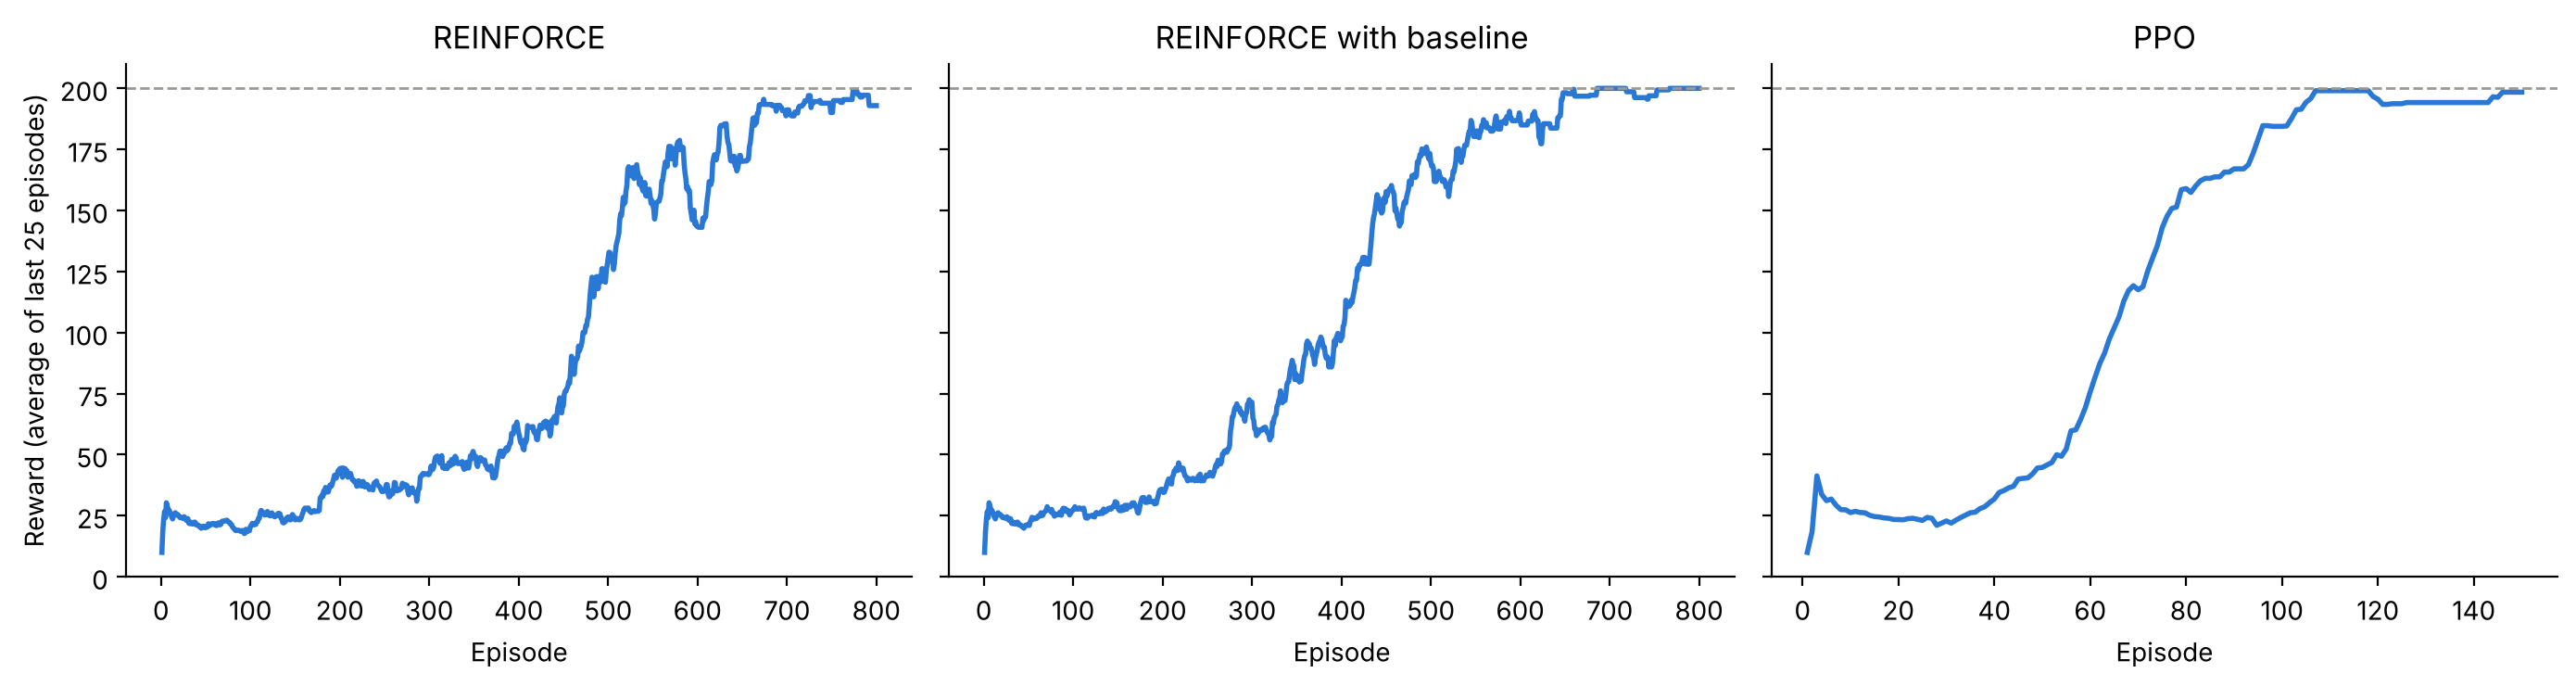

,Training episodes,First episode with 25-episode average ≥ 195,Test reward (mean ± std)
REINFORCE,800,674,179.5 ± 45.6
REINFORCE with baseline,800,646,200.0 ± 0.0
PPO,150,106,200.0 ± 0.0


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for ax, (name, (curve, _)) in zip(axes, results.items()):
    ax.plot(range(1, len(curve) + 1), curve, color="#2a78d6", lw=2)
    ax.axhline(200, color="#9b9a94", lw=1, ls="--")
    ax.set_title(name)
    ax.set_xlabel("Episode")
    ax.set_ylim(0, 210)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("Reward (average of last 25 episodes)")
plt.tight_layout()
plt.savefig("figures/policy_gradients.png", dpi=150)
plt.show()

summary = {
    name: {
        "Training episodes": len(curve),
        "First episode with 25-episode average ≥ 195": next((i + 1 for i, r in enumerate(curve) if r >= 195), "not reached"),
        "Test reward (mean ± std)": f"{np.mean(test):.1f} ± {np.std(test):.1f}",
    }
    for name, (curve, test) in results.items()
}
pd.DataFrame(summary).T